In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path(
    r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis"
)

(output_dir / "data" / "processed").mkdir(
    parents=True, exist_ok=True
)

(output_dir / "visualizations").mkdir(
    parents=True, exist_ok=True
)

print("India-US comparison environment ready!")

India-US comparison environment ready!


In [31]:
comparison_data = pd.DataFrame({
    "Country": ["India", "United States"],

    "Central_Bank": [
        "Reserve Bank of India",
        "Federal Reserve"
    ],

    "Inflation_Target_Percent": [4.0, 2.0],

    "Inflation_Target_Band": [
        "2%–6%",
        "2% long-run goal"
    ],

    "Billionaires_2024": [200, 813],
    "Billionaires_2025": [205, 902],

    "Happiness_Rank_2025": [118, 24]
})

comparison_data["Billionaire_Growth_Percent"] = (
    (comparison_data["Billionaires_2025"] -
     comparison_data["Billionaires_2024"])
    / comparison_data["Billionaires_2024"] * 100
)

display(comparison_data)

,Country,Central_Bank,Inflation_Target_Percent,Inflation_Target_Band,Billionaires_2024,Billionaires_2025,Happiness_Rank_2025,Billionaire_Growth_Percent
0,India,Reserve Bank of India,4.0,2%–6%,200,205,118,2.500000
1,United States,Federal Reserve,2.0,2% long-run goal,813,902,24,10.947109


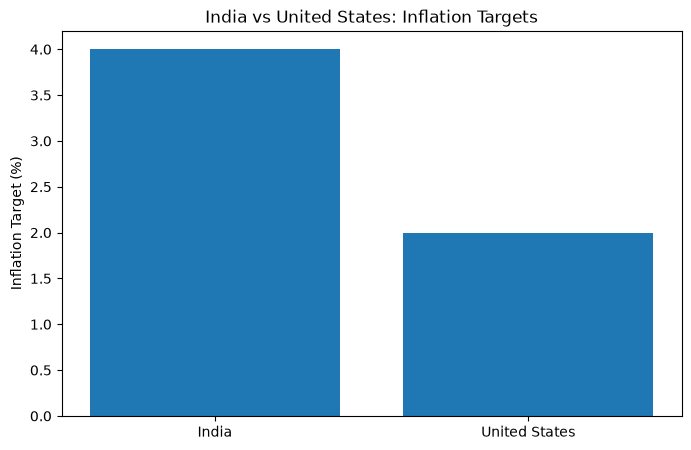

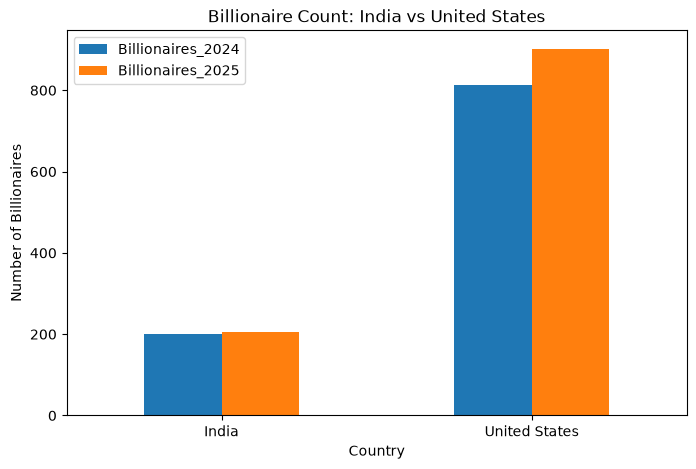

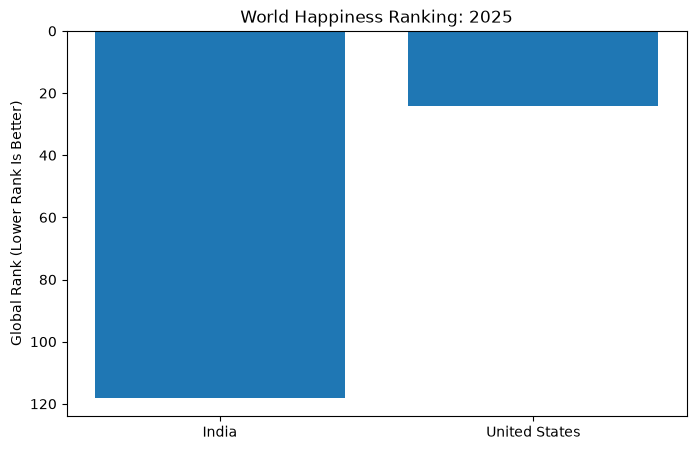

In [32]:
# 1. Inflation target comparison
plt.figure(figsize=(8, 5))
plt.bar(
    comparison_data["Country"],
    comparison_data["Inflation_Target_Percent"]
)
plt.title("India vs United States: Inflation Targets")
plt.ylabel("Inflation Target (%)")
plt.savefig(output_dir / "visualizations" / "inflation_target_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# 2. Billionaire count comparison
comparison_data.set_index("Country")[
    ["Billionaires_2024", "Billionaires_2025"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Billionaire Count: India vs United States")
plt.ylabel("Number of Billionaires")
plt.xticks(rotation=0)
plt.savefig(output_dir / "visualizations" / "billionaire_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


# 3. Happiness ranking comparison
plt.figure(figsize=(8, 5))
plt.bar(
    comparison_data["Country"],
    comparison_data["Happiness_Rank_2025"]
)
plt.title("World Happiness Ranking: 2025")
plt.ylabel("Global Rank (Lower Rank Is Better)")
plt.gca().invert_yaxis()
plt.savefig(output_dir / "visualizations" / "happiness_ranking_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

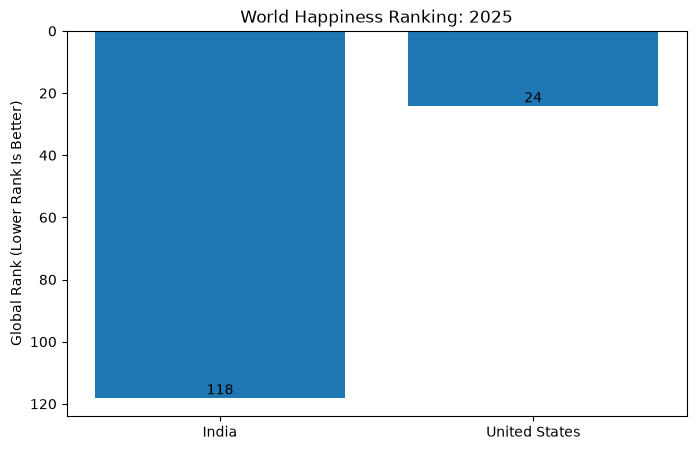

In [33]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_data["Country"],
    comparison_data["Happiness_Rank_2025"]
)

plt.title("World Happiness Ranking: 2025")
plt.ylabel("Global Rank (Lower Rank Is Better)")
plt.gca().invert_yaxis()

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )

plt.savefig(
    output_dir / "visualizations" / "happiness_ranking_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

# World Bank CPI inflation indicator
indicator = "FP.CPI.TOTL.ZG"

def get_inflation_data(country_code):
    url = (
        f"https://api.worldbank.org/v2/country/{country_code}/"
        f"indicator/{indicator}?date=2000:2024&format=json&per_page=100"
    )

    response = requests.get(url, timeout=30)
    response.raise_for_status()
    records = response.json()[1]

    return pd.DataFrame([
        {
            "Year": int(item["date"]),
            "Inflation": item["value"]
        }
        for item in records
        if item["value"] is not None
    ])

india_inflation = get_inflation_data("IND")
us_inflation = get_inflation_data("USA")

india_inflation["Country"] = "India"
us_inflation["Country"] = "United States"

inflation_data = pd.concat(
    [india_inflation, us_inflation],
    ignore_index=True
)

inflation_data = inflation_data.sort_values(
    ["Year", "Country"]
).reset_index(drop=True)

display(inflation_data.head(10))
print("Total records:", len(inflation_data))
print("Missing values:\n", inflation_data.isnull().sum())


,Year,Inflation,Country
0,2000,4.009436,India
1,2000,3.376857,United States
2,2001,3.779293,India
3,2001,2.826171,United States
4,2002,4.297152,India
5,2002,1.586032,United States
6,2003,3.805859,India
7,2003,2.270095,United States
8,2004,3.767252,India
9,2004,2.677237,United States


Total records: 50
Missing values:
 Year         0
Inflation    0
Country      0
dtype: int64


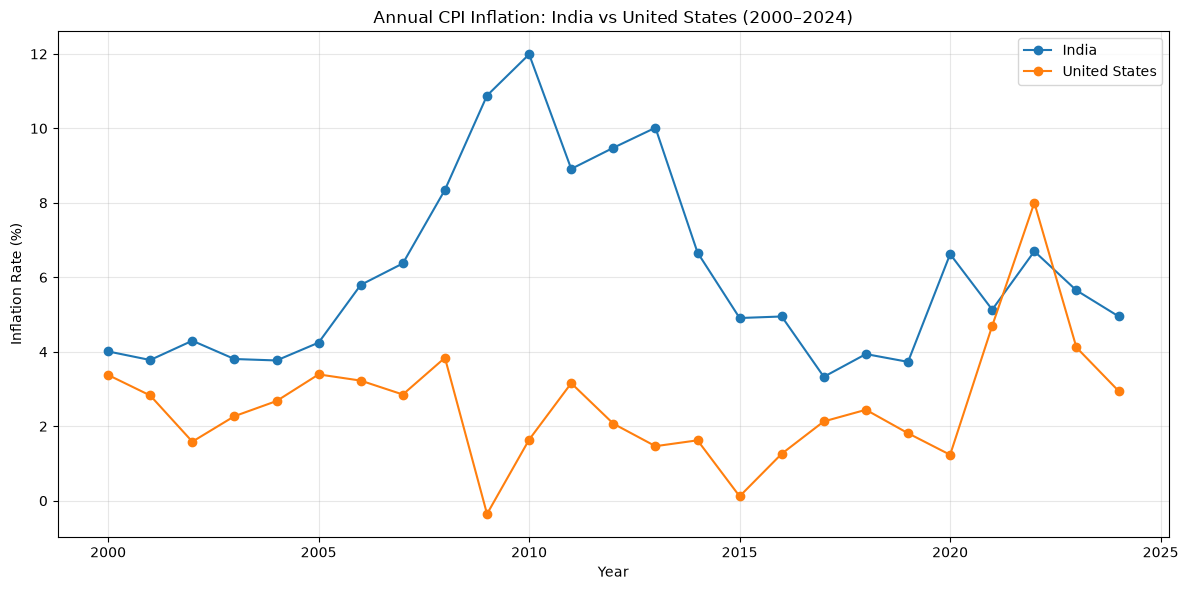

In [35]:
plt.figure(figsize=(12, 6))

for country in ["India", "United States"]:
    country_data = inflation_data[
        inflation_data["Country"] == country
    ]

    plt.plot(
        country_data["Year"],
        country_data["Inflation"],
        marker="o",
        label=country
    )

plt.title("Annual CPI Inflation: India vs United States (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Inflation Rate (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "visualizations" / "actual_inflation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
inflation_summary = (
    inflation_data.groupby("Country")["Inflation"]
    .agg(
        Average_Inflation="mean",
        Median_Inflation="median",
        Inflation_Volatility="std",
        Minimum_Inflation="min",
        Maximum_Inflation="max"
    )
    .round(2)
)

display(inflation_summary)

,Average_Inflation,Median_Inflation,Inflation_Volatility,Minimum_Inflation,Maximum_Inflation
Country,,,,,
India,6.09,5.13,2.49,3.33,11.99
United States,2.58,2.44,1.63,-0.36,8.00


In [37]:
# Save actual inflation data and summary
inflation_data.to_csv(
    output_dir / "data" / "processed" / "india_us_inflation_2000_2024.csv",
    index=False
)

inflation_summary.to_csv(
    output_dir / "data" / "processed" / "inflation_summary_india_us.csv"
)

print("Inflation datasets saved successfully!")

Inflation datasets saved successfully!


In [38]:
policy_comparison = pd.DataFrame({
    "Feature": [
        "Primary Objective",
        "Inflation Measure",
        "Inflation Target",
        "Main Policy Rate",
        "Decision Making Body",
        "Policy Framework"
    ],
    "India_RBI": [
        "Price stability with growth",
        "CPI",
        "4% (2%–6% band)",
        "Repo Rate",
        "Monetary Policy Committee",
        "Flexible Inflation Targeting"
    ],
    "United_States_Fed": [
        "Maximum employment and price stability",
        "PCE",
        "2% long-run goal",
        "Federal Funds Rate",
        "Federal Open Market Committee",
        "Dual Mandate"
    ]
})

display(policy_comparison)

policy_comparison.to_csv(
    output_dir / "data" / "processed" / "monetary_policy_comparison.csv",
    index=False
)

print("Monetary policy comparison saved successfully!")

,Feature,India_RBI,United_States_Fed
0,Primary Objective,Price stability with growth,Maximum employment and price stability
1,Inflation Measure,CPI,PCE
2,Inflation Target,4% (2%–6% band),2% long-run goal
3,Main Policy Rate,Repo Rate,Federal Funds Rate
4,Decision Making Body,Monetary Policy Committee,Federal Open Market Committee
5,Policy Framework,Flexible Inflation Targeting,Dual Mandate


Monetary policy comparison saved successfully!


In [39]:
from pathlib import Path

for folder in ["raw", "processed"]:
    path = output_dir / "data" / folder
    print(f"\n{folder.upper()} FILES:")
    for file in path.glob("*"):
        print(file.name)


RAW FILES:
inr_usd_annual_average_1971_1973.csv
inr_usd_fred_1973_2024.csv
inr_usd_historical_1947_1964.csv
inr_usd_transition_1971_1972.csv
Major Monetary Policy Rates and Reserve Requirements - Bank Rate, LAF (Repo, Reverse Repo, SDF and MSF) Rates, CRR & SLR.xlsx
r151_major_monetary_policy_rates_and_reserve_requirements_bank.csv
us_federal_funds_rate.csv

PROCESSED FILES:
annual_inr_depreciation_analysis.csv
historical_inr_usd_1947_1971.csv
india_us_inflation_2000_2024.csv
india_us_interest_rate_comparison.csv
inflation_summary_india_us.csv
inr_usd_forecast_2026_2050.csv
monetary_policy_comparison.csv
rbi_monetary_policy_rates_cleaned.csv


In [40]:
forecast_file = output_dir / "data" / "processed" / "inr_usd_forecast_2026_2050.csv"

print("Forecast file exists:", forecast_file.exists())
print("Expected location:", forecast_file)


Forecast file exists: True
Expected location: C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\data\processed\inr_usd_forecast_2026_2050.csv


In [41]:
visualization_dir = output_dir / "visualizations"

print("Visualization folder exists:", visualization_dir.exists())

for file in sorted(visualization_dir.glob("*.png")):
    print(file.name)

Visualization folder exists: True
actual_inflation_comparison.png
annual_exchange_rate.png
annual_inr_change.png
arima_actual_vs_predicted.png
billionaire_comparison.png
happiness_ranking_comparison.png
historical_inr_usd_1947_1971.png
india_us_interest_rate_comparison.png
inflation_target_comparison.png
inr_usd_forecast_2026_2050.png
monthly_exchange_rate.png
rbi_repo_rate_history.png
sarima_actual_vs_predicted.png
top_10_inr_depreciation_years.png


In [42]:
# Extract historical RBI monetary policy data

rbi = rbi_raw.iloc[8:, 1:9].copy()

rbi.columns = [
    "Effective_Date",
    "Bank_Rate",
    "Repo_Rate",
    "Reverse_Repo_Rate",
    "SDF_Rate",
    "MSF_Rate",
    "CRR",
    "SLR"
]

# Convert dates
rbi["Effective_Date"] = pd.to_datetime(
    rbi["Effective_Date"], errors="coerce"
)

# Convert rates to numeric values
rate_columns = [
    "Bank_Rate", "Repo_Rate", "Reverse_Repo_Rate",
    "SDF_Rate", "MSF_Rate", "CRR", "SLR"
]

for col in rate_columns:
    rbi[col] = pd.to_numeric(
        rbi[col].replace("-", pd.NA), errors="coerce"
    )

# Remove invalid dates and sort chronologically
rbi = (
    rbi.dropna(subset=["Effective_Date"])
       .sort_values("Effective_Date")
       .reset_index(drop=True)
)

print("Cleaned RBI dataset shape:", rbi.shape)
print("\nDate range:")
print(rbi["Effective_Date"].min(), "to", rbi["Effective_Date"].max())

display(rbi.head())
display(rbi.tail())

Cleaned RBI dataset shape: (260, 8)

Date range:
1935-07-05 00:00:00 to 2026-10-07 00:00:00


,Effective_Date,Bank_Rate,Repo_Rate,Reverse_Repo_Rate,SDF_Rate,MSF_Rate,CRR,SLR
0,1935-07-05,3.5,NaN,NaN,NaN,NaN,NaN,NaN
1,1935-11-28,3.0,NaN,NaN,NaN,NaN,NaN,NaN
2,1949-03-16,NaN,NaN,NaN,NaN,NaN,NaN,20.0
3,1951-11-15,3.5,NaN,NaN,NaN,NaN,NaN,NaN
4,1957-05-16,4.0,NaN,NaN,NaN,NaN,NaN,NaN


,Effective_Date,Bank_Rate,Repo_Rate,Reverse_Repo_Rate,SDF_Rate,MSF_Rate,CRR,SLR
255,2025-10-04,NaN,NaN,NaN,NaN,NaN,3.50,NaN
256,2025-11-01,NaN,NaN,NaN,NaN,NaN,3.25,NaN
257,2025-11-29,NaN,NaN,NaN,NaN,NaN,3.00,NaN
258,2025-12-05,5.50,5.25,NaN,5.00,5.50,NaN,NaN
259,2026-10-07,5.75,5.50,NaN,5.25,5.75,NaN,NaN


Repo rate observations: 72
Period: 2001-04-27 00:00:00 to 2026-10-07 00:00:00


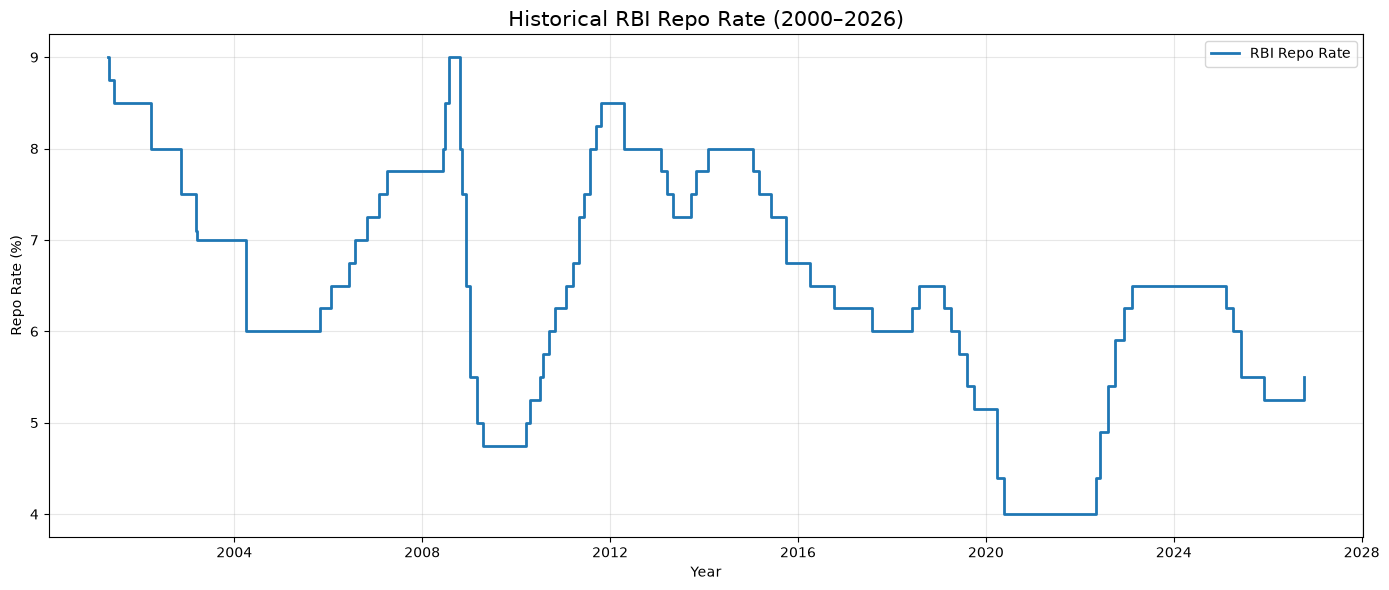

Graph saved: C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\rbi_repo_rate_history.png


In [43]:
import matplotlib.pyplot as plt

# Select records where Repo Rate is available
repo_data = rbi.dropna(subset=["Repo_Rate"]).copy()

print("Repo rate observations:", len(repo_data))
print("Period:", repo_data["Effective_Date"].min(),
      "to", repo_data["Effective_Date"].max())

# Create visualization
plt.figure(figsize=(14, 6))

plt.step(
    repo_data["Effective_Date"],
    repo_data["Repo_Rate"],
    where="post",
    label="RBI Repo Rate",
    linewidth=2
)

plt.title("Historical RBI Repo Rate (2000–2026)", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Repo Rate (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save visualization
output_path = project_dir / "visualizations" / "rbi_repo_rate_history.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print("Graph saved:", output_path)

In [44]:
rbi.to_csv(
    project_dir / "data" / "processed" / "rbi_monetary_policy_rates_cleaned.csv",
    index=False
)

print("Cleaned RBI dataset saved successfully.")

Cleaned RBI dataset saved successfully.


In [45]:
# Download US Federal Funds Rate from FRED

fred_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=FEDFUNDS"
)

fed = pd.read_csv(fred_url)

fed.columns = ["Date", "US_Federal_Funds_Rate"]

fed["Date"] = pd.to_datetime(fed["Date"])
fed["US_Federal_Funds_Rate"] = pd.to_numeric(
    fed["US_Federal_Funds_Rate"], errors="coerce"
)

fed = fed.dropna().sort_values("Date").reset_index(drop=True)

# Save original US data
fed.to_csv(
    project_dir / "data" / "raw" / "us_federal_funds_rate.csv",
    index=False
)

print("US dataset shape:", fed.shape)
print("Date range:", fed["Date"].min(), "to", fed["Date"].max())

display(fed.head())
display(fed.tail())

US dataset shape: (868, 2)
Date range: 1954-07-01 00:00:00 to 2026-10-01 00:00:00


,Date,US_Federal_Funds_Rate
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83


,Date,US_Federal_Funds_Rate
863,2026-06-01,3.63
864,2026-07-01,3.63
865,2026-08-01,3.63
866,2026-09-01,3.75
867,2026-10-01,3.88


In [46]:
# Compare RBI Repo Rate with US Federal Funds Rate

# Prepare RBI repo rate data
rbi_effective = (
    rbi.dropna(subset=["Repo_Rate"])
       .set_index("Effective_Date")["Repo_Rate"]
       .sort_index()
)

# Use complete months from May 2001
start_date = pd.Timestamp("2001-05-01")
end_date = min(rbi_effective.index.max(), fed["Date"].max())

daily_index = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

# Carry each RBI rate forward until the next effective date
rbi_daily = rbi_effective.reindex(daily_index).ffill()

# Calculate monthly average RBI repo rate
rbi_monthly = rbi_daily.resample("MS").mean()

# Prepare US monthly rate
fed_monthly = (
    fed.set_index("Date")["US_Federal_Funds_Rate"]
       .sort_index()
)

# Combine both datasets
comparison_monthly = pd.concat(
    [
        rbi_monthly.rename("India_Repo_Rate"),
        fed_monthly.rename("US_Federal_Funds_Rate")
    ],
    axis=1
).dropna()

# Calculate annual averages
comparison_annual = comparison_monthly.resample("YS").agg(
    ["mean", "count"]
)

# Keep only complete calendar years (12 months)
comparison_annual = comparison_annual[
    (comparison_annual[("India_Repo_Rate", "count")] == 12) &
    (comparison_annual[("US_Federal_Funds_Rate", "count")] == 12)
]

# Keep annual average rates
comparison_annual = comparison_annual.xs(
    "mean", axis=1, level=1
).reset_index()

comparison_annual.columns = [
    "Year",
    "India_Repo_Rate",
    "US_Federal_Funds_Rate"
]

# Save comparison dataset
comparison_annual.to_csv(
    project_dir / "data" / "processed" /
    "india_us_interest_rate_comparison.csv",
    index=False
)

print("Comparison dataset shape:", comparison_annual.shape)
print("Year range:",
      comparison_annual["Year"].min(),
      "to",
      comparison_annual["Year"].max())

display(comparison_annual.head())
display(comparison_annual.tail())

Comparison dataset shape: (24, 3)
Year range: 2002-01-01 00:00:00 to 2025-01-01 00:00:00


,Year,India_Repo_Rate,US_Federal_Funds_Rate
0,2002-01-01,8.051568,1.666667
1,2003-01-01,7.094624,1.127500
2,2004-01-01,6.247312,1.349167
3,2005-01-01,6.045699,3.213333
4,2006-01-01,6.776725,4.964167


,Year,India_Repo_Rate,US_Federal_Funds_Rate
19,2021-01-01,4.000000,0.080000
20,2022-01-01,4.898253,1.683333
21,2023-01-01,6.473958,5.024167
22,2024-01-01,6.500000,5.143333
23,2025-01-01,5.790486,4.212500


In [47]:
import pandas as pd
from pathlib import Path

project_dir = Path(r"C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis")

file_path = project_dir / "data" / "raw" / "Major Monetary Policy Rates and Reserve Requirements - Bank Rate, LAF (Repo, Reverse Repo, SDF and MSF) Rates, CRR & SLR.xlsx"

rbi_raw = pd.read_excel(file_path, header=None)

print("Dataset shape:", rbi_raw.shape)
display(rbi_raw.head(12))

Dataset shape: (270, 9)


C:\Users\Skyly\AppData\Local\Programs\Python\Python313\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7,8
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Major Monetary Policy Rates and Reserve Requir...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,(Per cent),NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Effective Date\n,Bank Rate,Fix Range LAF Rates,NaN,Standing Deposit Facility (SDF) Rate,Marginal Standing Facility (MSF) Rate,Cash Reserve Ratio (CRR),Statutory Liquidity Ratio (SLR)
6,NaN,NaN,NaN,Repo,Reverse Repo,NaN,NaN,NaN,NaN
7,NaN,1,2,3,4,5,6,7,8
8,NaN,2026-10-07 00:00:00,5.75,5.5,-,5.25,5.75,-,-
9,NaN,2025-12-05 00:00:00,5.5,5.25,-,5,5.5,-,-


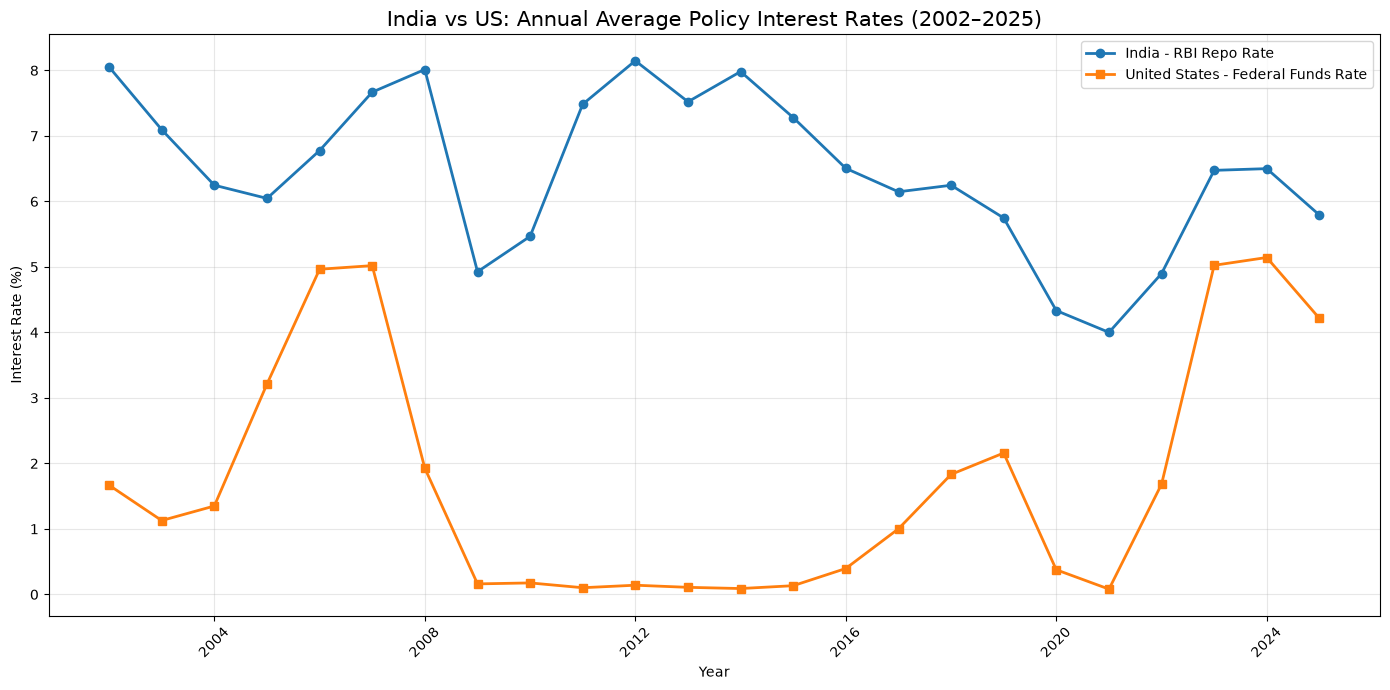

Chart saved successfully: C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\india_us_interest_rate_comparison.png


In [48]:
# India vs US Interest Rate Comparison

plt.figure(figsize=(14, 7))

plt.plot(
    comparison_annual["Year"],
    comparison_annual["India_Repo_Rate"],
    marker="o",
    linewidth=2,
    label="India - RBI Repo Rate"
)

plt.plot(
    comparison_annual["Year"],
    comparison_annual["US_Federal_Funds_Rate"],
    marker="s",
    linewidth=2,
    label="United States - Federal Funds Rate"
)

plt.title(
    "India vs US: Annual Average Policy Interest Rates (2002–2025)",
    fontsize=15
)

plt.xlabel("Year")
plt.ylabel("Interest Rate (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

output_path = (
    project_dir / "visualizations" /
    "india_us_interest_rate_comparison.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:", output_path)

## India vs United States: Monetary Policy Comparison (2002–2025)

The comparison of India's RBI Repo Rate and the US Federal Funds Rate
reveals differences in monetary policy approaches.

India generally maintained higher policy interest rates than the United
States. During the 2008 global financial crisis, the US reduced interest
rates significantly to support economic activity. During the COVID-19
pandemic, the US Federal Funds Rate approached zero, while India's repo
rate reached 4%.

From 2022 onward, both central banks increased interest rates in response
to inflationary pressures. By 2025, both countries had started reducing
rates.

Overall, the comparison highlights differences in inflation conditions,
monetary policy priorities, and economic responses to global events.

## Major Historical Events Influencing the Indian Rupee (1947–2024)

| Year / Period | Major Event | Impact on INR |
|---|---|---|
| 1949 | Devaluation of the Indian rupee alongside sterling | The rupee moved from approximately ₹3.32 to ₹4.07 per US dollar. |
| 1966 | Economic pressures, wars, droughts and foreign exchange shortages | The rupee was devalued by approximately 36.5%, moving from ₹4.75 to ₹7.50 per US dollar. |
| 1975 | Change in exchange-rate framework | India moved away from the pound sterling peg toward a basket of currencies. |
| 1991 | Balance of payments crisis and low foreign exchange reserves | The rupee underwent a major two-step devaluation in July 1991. |
| 1992–1993 | Introduction of LERMS and exchange-rate reforms | India moved toward a unified, market-determined exchange-rate system. |
| 2013 | US Federal Reserve tapering announcement | Capital outflows and market pressure contributed to approximately 17% rupee depreciation against the US dollar during the period described by RBI. |

### Interpretation

India's exchange-rate history reflects a gradual transition from a fixed and managed exchange-rate system toward a more market-oriented system.

Major currency adjustments were associated with domestic economic pressures, balance of payments difficulties, global financial developments, and changes in exchange-rate policy.

In [49]:
# Analyze annual INR depreciation from 1973–2024

exchange_rate = pd.read_csv(
    project_dir / "data" / "raw" /
    "inr_usd_fred_1973_2024.csv"
)

exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])

exchange_rate["Year"] = exchange_rate["Date"].dt.year

annual_exchange = (
    exchange_rate.groupby("Year")["INR_per_USD"]
    .mean()
    .reset_index()
)

annual_exchange["INR_Depreciation_%"] = (
    annual_exchange["INR_per_USD"].pct_change() * 100
)

annual_exchange.to_csv(
    project_dir / "data" / "processed" /
    "annual_inr_depreciation_analysis.csv",
    index=False
)

print("Dataset saved successfully!")

display(
    annual_exchange.sort_values(
        "INR_Depreciation_%", ascending=False
    ).head(10)
)

Dataset saved successfully!


,Year,INR_per_USD,INR_Depreciation_%
18,1991,22.719850,29.812137
19,1992,28.135092,23.834848
16,1989,16.207133,16.574459
39,2012,53.359108,14.474636
25,1998,41.329433,13.653112
11,1984,11.354800,12.358220
36,2009,48.319475,11.305895
20,1993,31.256917,11.095841
8,1981,8.679758,10.072507
40,2013,58.525500,9.682305


In [50]:
exchange_rate = pd.read_csv(
    project_dir / "data" / "raw" /
    "inr_usd_fred_1973_2024.csv"
)

print(exchange_rate.columns.tolist())
display(exchange_rate.head())

['Date', 'INR_per_USD']


,Date,INR_per_USD
0,1973-01-01,8.0041
1,1973-02-01,7.7538
2,1973-03-01,7.5465
3,1973-04-01,7.5462
4,1973-05-01,7.4927


In [51]:
# Annual INR/USD depreciation analysis (1973–2024)

exchange_rate["Date"] = pd.to_datetime(exchange_rate["Date"])

exchange_rate["Year"] = exchange_rate["Date"].dt.year

# Calculate annual average exchange rates
annual_exchange = (
    exchange_rate.groupby("Year")["INR_per_USD"]
    .mean()
    .reset_index()
)

# Calculate annual percentage change
annual_exchange["INR_Depreciation_%"] = (
    annual_exchange["INR_per_USD"].pct_change() * 100
)

# Save the dataset
output_file = (
    project_dir / "data" / "processed" /
    "annual_inr_depreciation_analysis.csv"
)

annual_exchange.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("Top 10 years with highest INR depreciation:")

display(
    annual_exchange.nlargest(
        10, "INR_Depreciation_%"
    )
)

Dataset saved successfully!
Top 10 years with highest INR depreciation:


,Year,INR_per_USD,INR_Depreciation_%
18,1991,22.719850,29.812137
19,1992,28.135092,23.834848
16,1989,16.207133,16.574459
39,2012,53.359108,14.474636
25,1998,41.329433,13.653112
11,1984,11.354800,12.358220
36,2009,48.319475,11.305895
20,1993,31.256917,11.095841
8,1981,8.679758,10.072507
40,2013,58.525500,9.682305


## Historical INR Depreciation: Key Findings

The analysis of annual average INR/USD exchange rates from 1973
through 2024 identifies 1991 as the year with the largest
percentage increase in INR per USD (29.81%).

The second-largest increase occurred in 1992 (23.83%),
during India's transition toward a more market-oriented
exchange-rate system.

Other notable years include 1989 (16.57%), 2012 (14.47%),
1998 (13.65%), 2009 (11.31%), and 2013 (9.68%).

These movements coincided with periods of domestic economic
adjustment, global financial instability, and changes in
international capital flows.

The results demonstrate that exchange-rate movements are
influenced by both domestic and international economic conditions.

Note: Percentage changes are calculated using annual average
INR-per-USD rates, not individual exchange-rate adjustments.

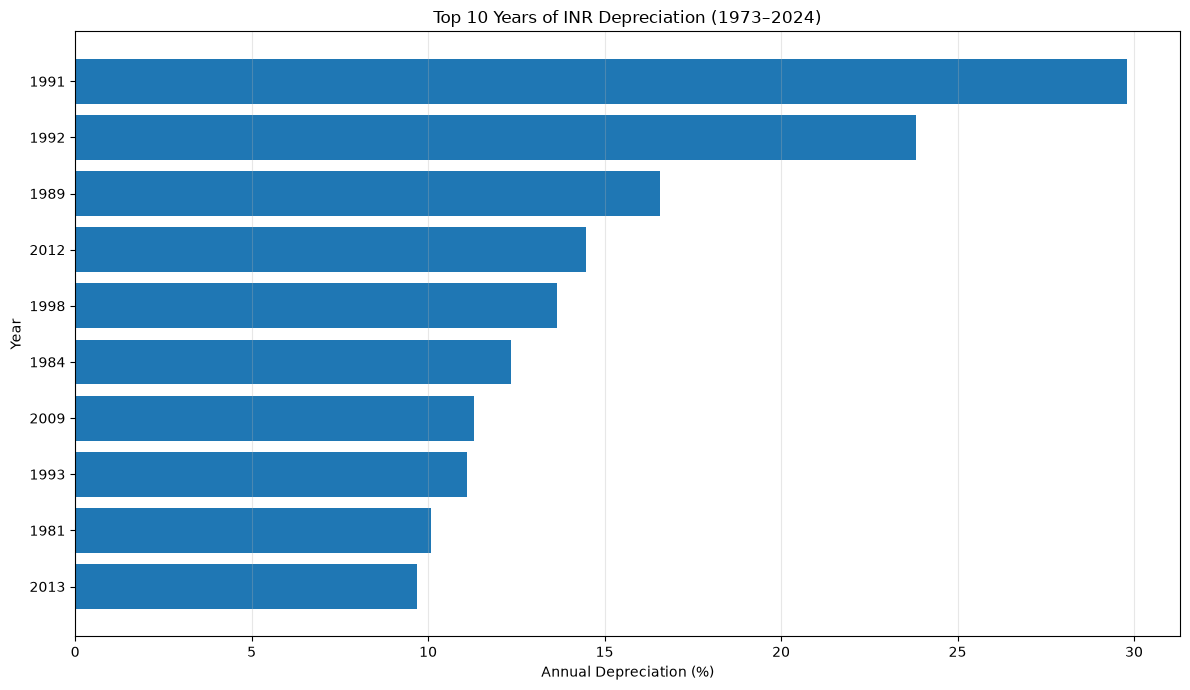

Chart saved: C:\Users\Skyly\Documents\GitHub\INR_USD_Trend_Analysis\visualizations\top_10_inr_depreciation_years.png


In [52]:
# Visualize top 10 INR depreciation years

top_10 = annual_exchange.nlargest(
    10, "INR_Depreciation_%"
).sort_values("INR_Depreciation_%")

plt.figure(figsize=(12, 7))

plt.barh(
    top_10["Year"].astype(str),
    top_10["INR_Depreciation_%"]
)

plt.title("Top 10 Years of INR Depreciation (1973–2024)")
plt.xlabel("Annual Depreciation (%)")
plt.ylabel("Year")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

output_path = (
    project_dir / "visualizations" /
    "top_10_inr_depreciation_years.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", output_path)